In [7]:
import astropy

In [8]:
import numpy as np

# Set up matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

from astropy.io import fits

In [9]:
image_file = "20261113T174736/20261113T174833.fits.fz"
hdu_list = fits.open(image_file)
image_data = hdu_list[1].data
hdu_list.close()

In [10]:
#on essaye de trouver le header de mon image pour avoir des infos sur : le temps d'exposition, la date, le filtre utilisé, etc. (j'ai pris que certaines informations qui me semblaient intéressantes)

header = hdu_list[1].header #tout se trouve dans le 1 car c'est la ou le fichier est compréssé, le 0 est vide
print(header["EXPTIME"]) #temps d'exposition
print(header["DATE-OBS"]) #date d'observation
print(header["FIELD"]) #nom du champ observé
print(header["RA-MNT"]) #ascension droite du télescope
print(header["DEC-MNT"]) #déclinaison du télescope
print(header["RA-RATE"]) #vitesse de l'ascension droite du télescope
print(header["FILTER"]) #filtre utilisé
#print(header["DEC-RATE"]) #vitesse de la déclinaison du télescope

9.0
2026-11-13T17:48:33.416
dy pegasis
347.55271
17.2182
1.0
RGGB


In [11]:
# On cherche quel découpage correspond au vrai canal vert

canal_00 = image_data[0::2, 0::2]
canal_01 = image_data[0::2, 1::2]
canal_10 = image_data[1::2, 0::2]
canal_11 = image_data[1::2, 1::2]

print("canal_00 :", np.median(canal_00))
print("canal_01 :", np.median(canal_01))
print("canal_10 :", np.median(canal_10))
print("canal_11 :", np.median(canal_11))

canal_00 : 7160.0
canal_01 : 7160.0
canal_10 : 7160.0
canal_11 : 7160.0


In [13]:
# On mesure une même étoile dans les 4 canaux pour essayer de comprendre comment marche la matrice de Bayer

x0 = 1640   # position x de l'étoile (lue sur l'image), nombre PAIR
y0 = 974   # position y de l'étoile (lue sur l'image), nombre PAIR

boite = image_data[y0-20 : y0+20, x0-20 : x0+20].astype(float)
print("max dans la boîte :", np.max(boite))

boite = boite - np.median(boite)

print("somme 00 :", np.sum(boite[0::2, 0::2]))
print("somme 01 :", np.sum(boite[0::2, 1::2]))
print("somme 10 :", np.sum(boite[1::2, 0::2]))
print("somme 11 :", np.sum(boite[1::2, 1::2]))

max dans la boîte : 65532.0
somme 00 : 1340012.0
somme 01 : 1328252.0
somme 10 : 1307252.0
somme 11 : 1326208.0


In [ ]:
#les valeurs précédentes sont toutes plus ou moins égales ce qui nous confirme que on bosse sur une photo monochrome malgré le header RGGB

In [16]:
from astropy.stats import sigma_clipped_stats 

#ici on doit extraire le canal vert de l'image pour supprimer le damier, puis on va utiliser photutils pour trouver les étoiles dans l'image et ensuite on va chercher l'étoile pegasis dans la liste des étoiles trouvées
green_channel = image_data #on a vérifié dans la cellule d'avant et on n'a pas de matrice de Bayer, donc on travaille avec l'image complète
std_green = sigma_clipped_stats(green_channel, sigma=3.0)[2] #calcule l'écart type des pixels du canal vert en utilisant la méthode sigma-clipping pour éliminer les valeurs aberrantes
mean_green = sigma_clipped_stats(green_channel, sigma=3.0)[0] #calcule la moyenne des pixels du canal vert en utilisant la méthode sigma-clipping pour éliminer les valeurs aberrantes

In [25]:
from photutils.detection import DAOStarFinder

#on veut trouver les coordonnées de l'étoile pegasis, donc on utilise DAOStarFinder de la bibliothèque photutils pour trouver les étoiles dans l'image et ensuite on va chercher l'étoile pegasis dans la liste des étoiles trouvées
finder = DAOStarFinder(fwhm=4, threshold=5.*std_green)
stars = finder.find_stars(green_channel - mean_green) #on veut enlever l'effet du fond de ciel, donc on soustrait la moyenne de l'image pour ne garder que les étoiles aka supprimer l'effet du a la matrice de Bayer (damier) et le bruit de fond
print(len(stars)) #nous dit combien d'étoiles ont été trouvées dans l'image
print(stars[5:10]) #nous donne les coordonnées des étoiles trouvées dans l'image, on peut ensuite chercher l'étoile pegasis dans cette liste

679
 id     x_centroid     ...         mag             daofind_mag     
--- ------------------ ... ------------------- --------------------
  6  3822.577735289467 ... -13.309669383623051  -2.8368905377737272
  7 1548.3844950390614 ... -11.373936925397384  -0.2129716498501214
  8 1599.5962559630384 ... -11.638293144311413  -0.5114860942591618
  9  3314.432913798389 ...  -9.740021693939278 -0.16347523289553909
 10 1646.0429966992604 ... -11.330694969655113 -0.18134033623946275


In [26]:
#il faut qu'on fasse l'analogie coordonnées - pixels (plate solving) pour trouver l'étoile pegasis dans l'image, puis on pourra faire la photométrie de l'étoile pegasis pour avoir sa courbe de lumière
from astropy.coordinates import SkyCoord
print(SkyCoord.from_name("DY Peg")) #on met le nom de l'étoile que l'on à observé pour avoir ses coordonées
print(header["XPIXSZ"]) #taille d'un pixel en micrometers
print(header["INSTRUME"]) #nom de l'instrument utilisé pour l'observation
#après j'installe twirl pour faire correspondre les coordonnées des étoiles "dans la vraie vie" avec les coordonnées pixel de mon image


<SkyCoord (ICRS): (ra, dec) in deg
    (347.21327418, 17.21555487)>
4.63
081c470016020900


In [27]:
print(stars.colnames) #nous montre le nom de la colonne dont on a besoin
#mtn on veut les étoiles les plus brillantes de l'image, donc on va trier la liste des étoiles trouvées par leur flux (brightness) et on va prendre les 20 premières étoiles les plus brillantes
stars.sort('flux', reverse=True) #trie les étoiles par flux (brightness)
#twirl veut un tableau NumPy 2D de forme (N, 2) contenant les positions (x, y) des 20 étoiles les plus brillantes de ton image.
print(stars[0:20]) #on affiche les 20 étoiles les plus brillantes de l'image pour ensuite les utiliser dans twirl pour faire l'astrométrie de l'image et trouver l'étoile pegasis

['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']
 id     x_centroid     ...         mag             daofind_mag    
--- ------------------ ... ------------------- -------------------
634  3457.703705268686 ... -15.061323573883028 -1.8110629577738053
485  2470.956454189857 ...  -15.05678277990912  -2.155063020520997
516 3848.6965192574535 ... -15.042874177141472 -2.1036044392445286
391 1379.7448062156384 ...  -15.03619908458407 -2.0687418322093816
327 2051.9255642885587 ... -15.029119151117653  -2.379989452413787
101 3419.8753449916344 ... -14.996078429502814 -2.2649424366357183
368  359.9971438710277 ... -14.980887329723478  -2.658756293090938
370 3477.0103155774723 ... -14.980387746626773 -2.5440144744265343
488  560.6371350234815 ...  -14.96795706944166 -1.8944452985501785
518 3849.0961787791352 ...  -14.92099092073984 -2.0745388783719467
344  3702.933043091767 ... -14.901265672277361  -2.818566893732042
108

In [28]:
#on récupère x_centroid et y_centroid des 20 étoiles les plus brillantes et on les mets dans un tableau NumPy 2D de forme (N, 2) contenant les positions (x, y) des 20 étoiles les plus brillantes de ton image.
x = stars['x_centroid'][0:30]
y = stars['y_centroid'][0:30]
positions = np.vstack((x, y)).T #on met les coordonnées x et y dans un tableau NumPy 2D de forme (N, 2) contenant les positions (x, y) des 20 étoiles les plus brillantes de ton image.
print(positions.shape) #on vérifie que le tableau s'affiche correctement

(30, 2)


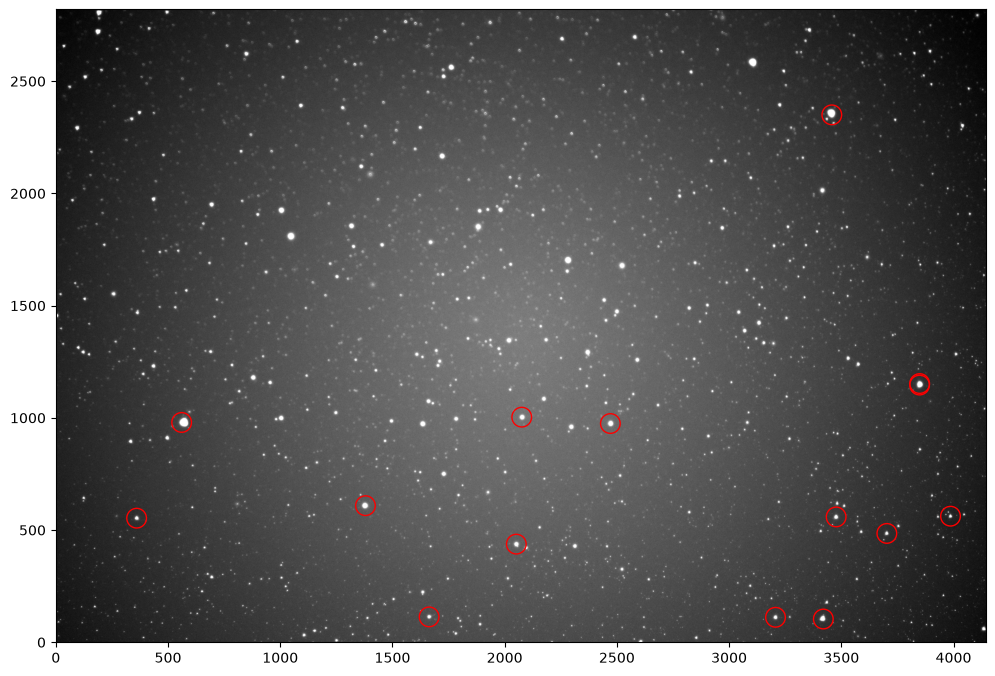

In [29]:
# On vérifie quelles étoiles on donne à twirl

from astropy.visualization import ZScaleInterval

zscale = ZScaleInterval()
vmin, vmax = zscale.get_limits(green_channel)

plt.figure(figsize=(12, 9))
plt.imshow(green_channel, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
plt.scatter(positions[:15, 0], positions[:15, 1], s=200, edgecolor="red", facecolor="none")
plt.show()

In [30]:
center = SkyCoord(header["RA-MNT"], header["DEC-MNT"], unit="deg") #on met les coordonnées du centre de l'image pour que twirl puisse faire l'astrométrie de l'image et trouver l'étoile pegasis
print(center)

from astroquery.mast import Catalogs

result = Catalogs.query_criteria(coordinates=center, radius="6deg", catalog="Tic", Tmag=[-2, 10]) #on prends que les étoiles de mag entre -2 et 10 autour de notre centre (dans la vraie vie)
result.sort('Tmag')
datax = result['ra'].data[:60]
datay = result['dec'].data[:60]
rad_np = np.column_stack((datax, datay))

<SkyCoord (ICRS): (ra, dec) in deg
    (347.55271, 17.2182)>


In [31]:
from twirl import compute_wcs

pos_np = np.array(positions, dtype=float) #une erreur me disait que les tableaux n'étaient pas des numpy donc je make sure
wcs = compute_wcs(pos_np[:15],rad_np[:40])
print(wcs)

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 347.8281491306254 17.78695875456851
CRPIX : 1442.4130154391232 570.9341885912248
CD1_1 CD1_2  : 0.00035278364704184264 -0.0031093161775618966
CD2_1 CD2_2  : 0.003106089387833825 0.0003718115649767433
NAXIS : 2471  1004


In [32]:
import matplotlib.patches as patches

# 1. Récupérer les coordonnées célestes de DY Pegasi et les convertir en pixels
target_coord = SkyCoord.from_name("DY Peg")
x_target, y_target = wcs.world_to_pixel(target_coord)
print(f"DY Pegasi se trouve aux pixels : x = {x_target:.1f}, y = {y_target:.1f}")

DY Pegasi se trouve aux pixels : x = 1237.9, y = 735.8


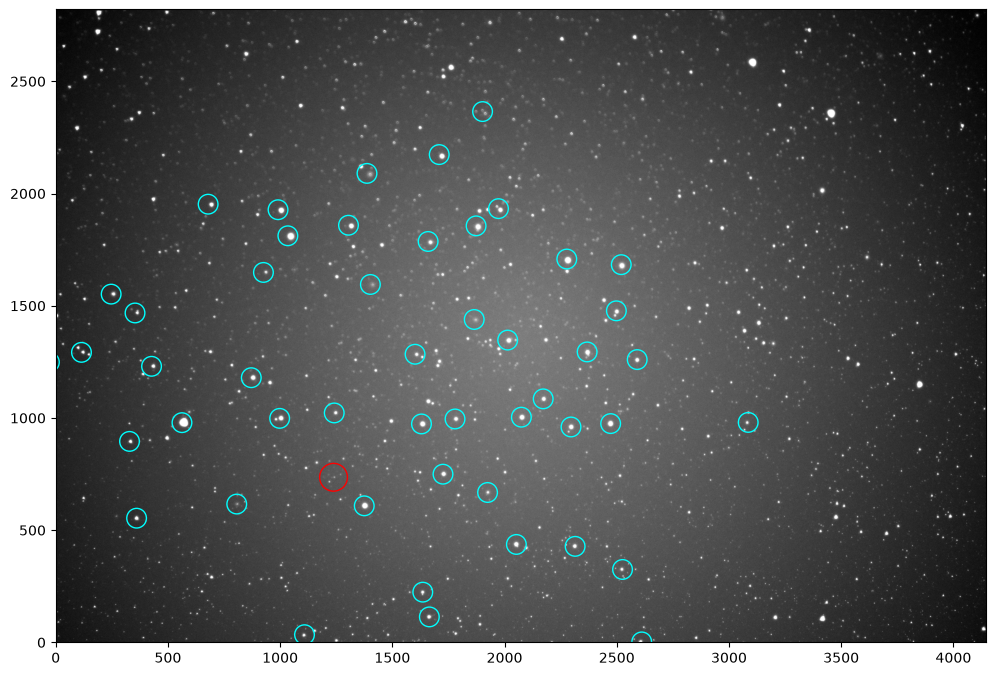

In [33]:
# On vérifie le WCS : les étoiles du catalogue doivent tomber sur les étoiles de l'image

x_cat, y_cat = wcs.world_to_pixel_values(rad_np[:, 0], rad_np[:, 1])

plt.figure(figsize=(12, 9))
plt.imshow(green_channel, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
plt.scatter(x_cat, y_cat, s=200, edgecolor="cyan", facecolor="none")
plt.scatter(x_target, y_target, s=400, edgecolor="red", facecolor="none")
plt.xlim(0, green_channel.shape[1])
plt.ylim(0, green_channel.shape[0])
plt.show()

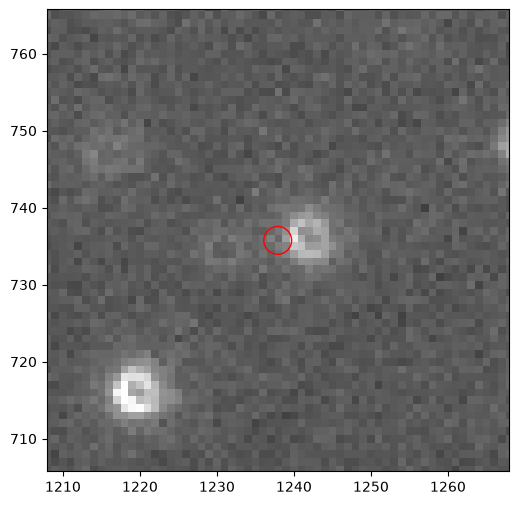

In [34]:
# Comme sur l'image précédente on ne voit pas bien Pegasis on zoom sur la position de DY Peg pour vérifier qu'on y voit qq chose

plt.figure(figsize=(6, 6))
plt.imshow(green_channel, cmap="gray", vmin=vmin, vmax=vmax, origin="lower", interpolation="nearest")
plt.scatter(x_target, y_target, s=400, edgecolor="red", facecolor="none")
plt.xlim(x_target - 30, x_target + 30)
plt.ylim(y_target - 30, y_target + 30)
plt.show()

In [ ]:
#on voit bien Pegasis, elle est légerement décalée mais on va régler ca aux étapes d'après
#on peut aussi noter que l’étoile fait environ 10 pixels de diamètre, et notre ouverture de rayon 5 sera sans doute trop petite pour contenir tout l’anneau.
#il y a une étoile juste à coté on doit bien y faire gaffe

Position corrigée de DY Peg : x = 1241.180302962599 , y = 736.1424549801153


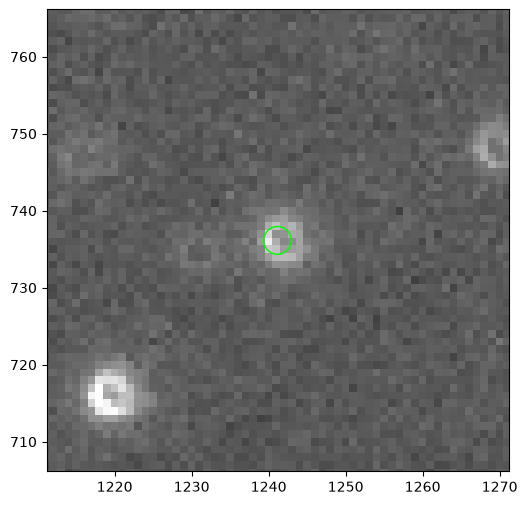

In [36]:
# On recentre précisément sur DY Peg avec le centroïde et en prenant en compte le fond de l'image

from photutils.centroids import centroid_sources, centroid_com

fond_local = np.median(green_channel[int(y_target)-30 : int(y_target)+30, int(x_target)-30 : int(x_target)+30]) #on prend le fond autour de pegasis comme référence car il varie dans toute l'image

x_vrai, y_vrai = centroid_sources(green_channel - fond_local, x_target, y_target, box_size=11, centroid_func=centroid_com)
x_vrai = x_vrai[0]
y_vrai = y_vrai[0]

x_vrai, y_vrai = centroid_sources(green_channel - fond_local, x_vrai, y_vrai, box_size=11, centroid_func=centroid_com) #on réfait le même calcul avec les valeurs d'avant pour affiner la précision
x_vrai = x_vrai[0]
y_vrai = y_vrai[0]
print("Position corrigée de DY Peg : x =", x_vrai, ", y =", y_vrai)

plt.figure(figsize=(6, 6))
plt.imshow(green_channel, cmap="gray", vmin=vmin, vmax=vmax, origin="lower", interpolation="nearest")
plt.scatter(x_vrai, y_vrai, s=400, edgecolor="lime", facecolor="none")
plt.xlim(x_vrai - 30, x_vrai + 30)
plt.ylim(y_vrai - 30, y_vrai + 30)
plt.show()

In [ ]:
#maintenant qu'on est bien centré sur l'image on peut passer au calcul de flux

Fond par pixel : 7612.0
Flux de DY Peg : 95191.4567567209
Bruit sur le flux : 2019.971420030493
Rapport signal/bruit : 47.12515029310856


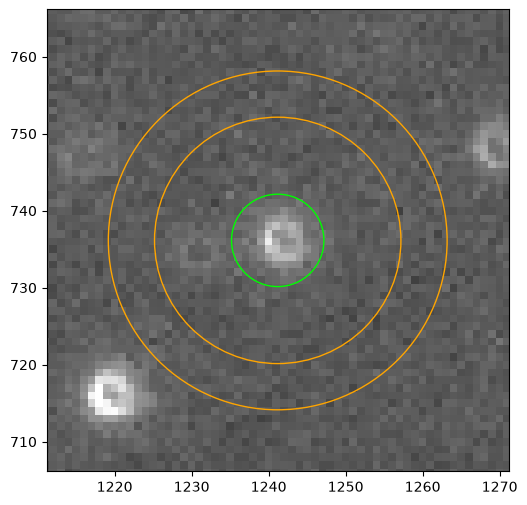

In [37]:
# Photométrie d'ouverture sur DY Peg

from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry, ApertureStats

ouverture = CircularAperture((x_vrai, y_vrai), r=6) #entoure l'étoile qu'on étudie
anneau = CircularAnnulus((x_vrai, y_vrai), r_in=16, r_out=22) #l'anneau est la pour nous aider à retirer l'effet parasite du bruit et du fond

stats_anneau = ApertureStats(green_channel, anneau)
fond_par_pixel = stats_anneau.median
bruit_par_pixel = stats_anneau.std

phot = aperture_photometry(green_channel, ouverture)
flux_dy = phot["aperture_sum"][0] - fond_par_pixel * ouverture.area
bruit_flux = bruit_par_pixel * np.sqrt(ouverture.area)

print("Fond par pixel :", fond_par_pixel)
print("Flux de DY Peg :", flux_dy)
print("Bruit sur le flux :", bruit_flux)
print("Rapport signal/bruit :", flux_dy / bruit_flux)

plt.figure(figsize=(6, 6))
plt.imshow(green_channel, cmap="gray", vmin=vmin, vmax=vmax, origin="lower", interpolation="nearest")
ouverture.plot(color="lime")
anneau.plot(color="orange")
plt.xlim(x_vrai - 30, x_vrai + 30)
plt.ylim(y_vrai - 30, y_vrai + 30)
plt.show()

In [ ]:
#mtn qu'on a le bon flux et qu'on mesure la bonne étoile, on doit choisir une étoile de référence qui nous permetra d'annuler le changement de flux du au changement d'atmosphère

Nombre d'étoiles candidates : 791


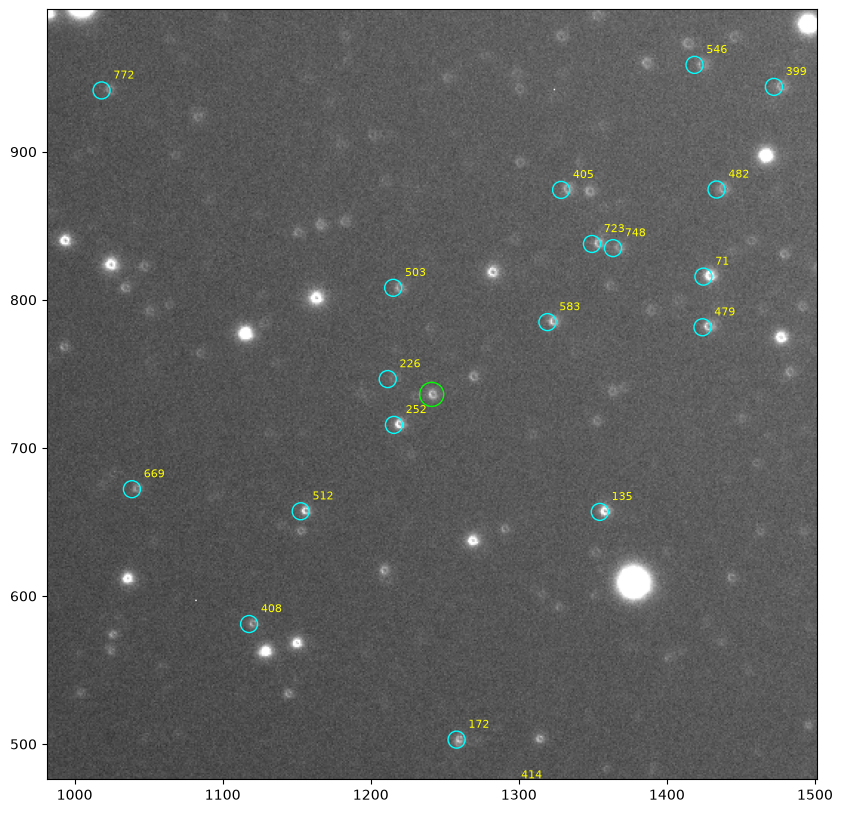

In [40]:
# On cherche des étoiles de comparaison de luminosité proche de DY Peg, autour d'elle

result_comp = result[result["Tmag"] > 9] #attention ces données proviennent de l'autre notebook !! quand les serveurs ne seront pas down il faudra mettre result_comp = Catalogs.query_criteria(coordinates=target_coord, radius="0.8deg", catalog="Tic", Tmag=[9, 11])
print("Nombre d'étoiles candidates :", len(result_comp))

x_comp, y_comp = wcs.world_to_pixel_values(result_comp["ra"].data, result_comp["dec"].data)

plt.figure(figsize=(10, 10))
plt.imshow(green_channel, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
plt.scatter(x_comp, y_comp, s=150, edgecolor="cyan", facecolor="none")
for i in range(len(x_comp)):
    plt.text(x_comp[i] + 8, y_comp[i] + 8, str(i), color="yellow", fontsize=8, clip_on=True)
plt.scatter(x_vrai, y_vrai, s=300, edgecolor="lime", facecolor="none")
plt.xlim(x_vrai - 260, x_vrai + 260)
plt.ylim(y_vrai - 260, y_vrai + 260)
plt.show()

In [ ]:
#à partir de la photo précédente, on choisit des étoiles (5) un peu isolées et assez lumineuses comme étoiles de référence pour notre calcul final

In [41]:
# On mesure le flux des étoiles de comparaison, avec exactement la même méthode que pour DY Peg

indices_comp = [252, 503, 583, 479, 482] #indices des étoiles qu'on a choisi à partir de l'image précédente

#on calcule les flux de ses étoiles de ref de la même manière que ce qu'on a fait pour notre étoile target

for i in indices_comp:
    xc = x_comp[i]
    yc = y_comp[i]
    fond = np.median(green_channel[int(yc)-30 : int(yc)+30, int(xc)-30 : int(xc)+30])

    xc, yc = centroid_sources(green_channel - fond, xc, yc, box_size=11, centroid_func=centroid_com)
    xc, yc = centroid_sources(green_channel - fond, xc[0], yc[0], box_size=11, centroid_func=centroid_com)
    xc = xc[0]
    yc = yc[0]

    ouv = CircularAperture((xc, yc), r=6)
    ann = CircularAnnulus((xc, yc), r_in=16, r_out=22)
    stats = ApertureStats(green_channel, ann)
    phot = aperture_photometry(green_channel, ouv)

    flux = phot["aperture_sum"][0] - stats.median * ouv.area
    snr = flux / (stats.std * np.sqrt(ouv.area))

    print("Étoile", i, ": x =", round(xc, 1), " y =", round(yc, 1), " flux =", round(flux), " S/B =", round(snr, 1), " Tmag =", result_comp["Tmag"][i])

Étoile 252 : x = 1219.1  y = 716.1  flux = 144029  S/B = 66.4  Tmag = 9.39789
Étoile 503 : x = 1219.0  y = 808.0  flux = 70324  S/B = 35.3  Tmag = 9.688
Étoile 583 : x = 1323.0  y = 785.8  flux = 106141  S/B = 56.3  Tmag = 9.78085
Étoile 479 : x = 1428.1  y = 782.1  flux = 108681  S/B = 55.6  Tmag = 9.66244
Étoile 482 : x = 1437.8  y = 875.1  flux = 77560  S/B = 40.2  Tmag = 9.6652


In [47]:
# Fonction qui mesure le flux d'une étoile dans une image, à partir d'une position approximative

def mesurer_flux(image, x, y):
    fond = np.median(image[int(y)-30 : int(y)+30, int(x)-30 : int(x)+30])

    xc, yc = centroid_sources(image - fond, x, y, box_size=11, centroid_func=centroid_com)
    ok = np.isfinite(xc[0]) and np.isfinite(yc[0]) and abs(xc[0] - x) < 6 and abs(yc[0] - y) < 6
    if not ok:
        return np.nan, x, y

    xc, yc = centroid_sources(image - fond, xc[0], yc[0], box_size=11, centroid_func=centroid_com)
    ok = np.isfinite(xc[0]) and np.isfinite(yc[0]) and abs(xc[0] - x) < 6 and abs(yc[0] - y) < 6
    if not ok:
        return np.nan, x, y

    xc = xc[0]
    yc = yc[0]

    ouv = CircularAperture((xc, yc), r=6)
    ann = CircularAnnulus((xc, yc), r_in=16, r_out=22)
    stats = ApertureStats(image, ann)
    phot = aperture_photometry(image, ouv)

    flux = phot["aperture_sum"][0] - stats.median * ouv.area
    return flux, xc, yc


# Test : on doit retrouver exactement le résultat de DY Peg
flux_test, x_test, y_test = mesurer_flux(green_channel, x_target, y_target)
print("Flux :", flux_test, " position :", x_test, y_test)

Flux : 95191.4567567209  position : 1241.180302962599 736.1424549801153


In [53]:
# Boucle sur toutes les images : on retrouve le décalage du champ grâce à l'étoile la plus brillante

import glob
from astropy.time import Time
import astropy.units as u
from scipy.ndimage import gaussian_filter

def trouver_guide(image):
    petite = image[::4, ::4].astype(float)
    lisse = gaussian_filter(petite, 3)
    iy, ix = np.unravel_index(np.argmax(lisse), lisse.shape)
    x0 = ix * 4
    y0 = iy * 4
    fond = np.median(image[max(y0-50, 0) : y0+50, max(x0-50, 0) : x0+50])
    xg, yg = centroid_sources(image - fond, x0, y0, box_size=61, centroid_func=centroid_com)
    return xg[0], yg[0]

fichiers = sorted(glob.glob("20261113T174736/*.fits.fz"))

# Positions de référence dans la 1re image : DY Peg puis les 5 comparaisons
x_ref = [x_vrai]
y_ref = [y_vrai]
for i in indices_comp:
    x_ref.append(x_comp[i])
    y_ref.append(y_comp[i])

# Position de l'étoile guide dans la 1re image
x_guide_ref, y_guide_ref = trouver_guide(green_channel)
print("Étoile guide dans la 1re image :", x_guide_ref, y_guide_ref)

temps = []
flux_tous = []

# Dernière position mesurée avec succès pour chaque étoile, et décalage de la guide à ce moment-là
x_der = list(x_ref)
y_der = list(y_ref)
dx_der = [0, 0, 0, 0, 0, 0]
dy_der = [0, 0, 0, 0, 0, 0]

for fichier in fichiers:
    data = fits.getdata(fichier, ext=1)
    header_im = fits.getheader(fichier, ext=1)

    t = Time(header_im["DATE-OBS"]) + header_im["EXPTIME"] / 2 * u.s
    temps.append(t.jd)

    # 1. Décalage du champ par rapport à la 1re image
    x_guide, y_guide = trouver_guide(data)
    dx = x_guide - x_guide_ref
    dy = y_guide - y_guide_ref

    # 2. Mesure des 6 étoiles
    flux_image = []
    for k in range(len(x_ref)):
        x_pred = x_der[k] + (dx - dx_der[k])
        y_pred = y_der[k] + (dy - dy_der[k])

        flux, xk, yk = mesurer_flux(data, x_pred, y_pred)

        if np.isfinite(flux):
            x_der[k] = xk
            y_der[k] = yk
            dx_der[k] = dx
            dy_der[k] = dy

        flux_image.append(flux)

    flux_tous.append(flux_image)
    print(fichier, " décalage :", round(dx, 1), round(dy, 1), " flux :", np.round(flux_image))

Étoile guide dans la 1re image : 570.3628564052208 979.9981201684009
20261113T174736\20261113T174833.fits.fz  décalage : 0.0 0.0  flux : [ 95913. 144029.  70324. 106141. 108681.  77560.]
20261113T174736\20261113T174848.fits.fz  décalage : 0.4 -0.4  flux : [ 93657. 144865.  73005. 111291. 115928.  74451.]
20261113T174736\20261113T174903.fits.fz  décalage : 0.5 -1.1  flux : [ 94612. 144422.  71856. 110949. 111274.  74828.]
20261113T174736\20261113T174919.fits.fz  décalage : 0.4 -1.4  flux : [ 93052. 143947.  71222. 109981. 117305.  73989.]
20261113T174736\20261113T174934.fits.fz  décalage : 0.3 -1.9  flux : [ 95061. 147131.  74600. 104916. 121013.  77411.]
20261113T174736\20261113T174949.fits.fz  décalage : 0.1 -2.5  flux : [ 93029. 146176.  71909. 114554. 113571.  74940.]
20261113T174736\20261113T175004.fits.fz  décalage : -0.1 -2.9  flux : [ 91933. 147413.  67603. 103953. 117111.  72038.]
20261113T174736\20261113T175020.fits.fz  décalage : -0.4 -3.3  flux : [ 88848. 144006.  69064. 112

Nombre d'images : 476
Nombre de points valides : 476
Dispersion de la courbe de contrôle : 0.03329282424941156


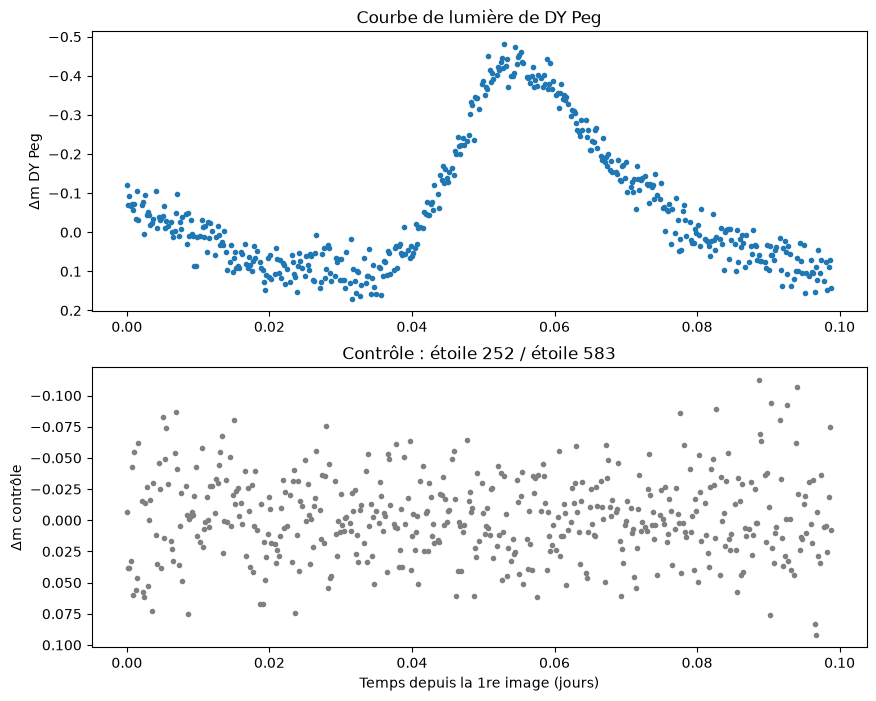

In [54]:
# Courbe de lumière de DY Peg + courbe de contrôle

flux_np = np.array(flux_tous)      # tableau : une ligne par image, 6 colonnes (DY Peg + 5 comparaisons)
temps_np = np.array(temps)

t_rel = temps_np - temps_np[0]     # temps en jours depuis la 1re image

flux_dy = flux_np[:, 0]
flux_comp_total = np.sum(flux_np[:, 1:], axis=1)

delta_m = -2.5 * np.log10(flux_dy / flux_comp_total)
delta_m = delta_m - np.nanmedian(delta_m)

controle = -2.5 * np.log10(flux_np[:, 1] / flux_np[:, 3])
controle = controle - np.nanmedian(controle)

print("Nombre d'images :", len(delta_m))
print("Nombre de points valides :", np.sum(np.isfinite(delta_m)))
print("Dispersion de la courbe de contrôle :", np.nanstd(controle))

plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.plot(t_rel, delta_m, ".")
plt.gca().invert_yaxis()
plt.ylabel("Δm DY Peg")
plt.title("Courbe de lumière de DY Peg")

plt.subplot(2, 1, 2)
plt.plot(t_rel, controle, ".", color="gray")
plt.gca().invert_yaxis()
plt.xlabel("Temps depuis la 1re image (jours)")
plt.ylabel("Δm contrôle")
plt.title("Contrôle : étoile 252 / étoile 583")

plt.show()

In [55]:
# Sauvegarde des résultats dans un fichier CSV

from astropy.table import Table

resultats = Table()
resultats["temps_jd"] = temps_np
resultats["flux_dy"] = flux_np[:, 0]
for j in range(len(indices_comp)):
    resultats["flux_comp_" + str(indices_comp[j])] = flux_np[:, j + 1]
resultats["delta_m"] = delta_m

resultats.write("courbe_dy_peg.csv", overwrite=True)
print("Sauvegardé :", len(resultats), "lignes")

Sauvegardé : 476 lignes


Médiane avant : 7128.0
Médiane après : 7132.0


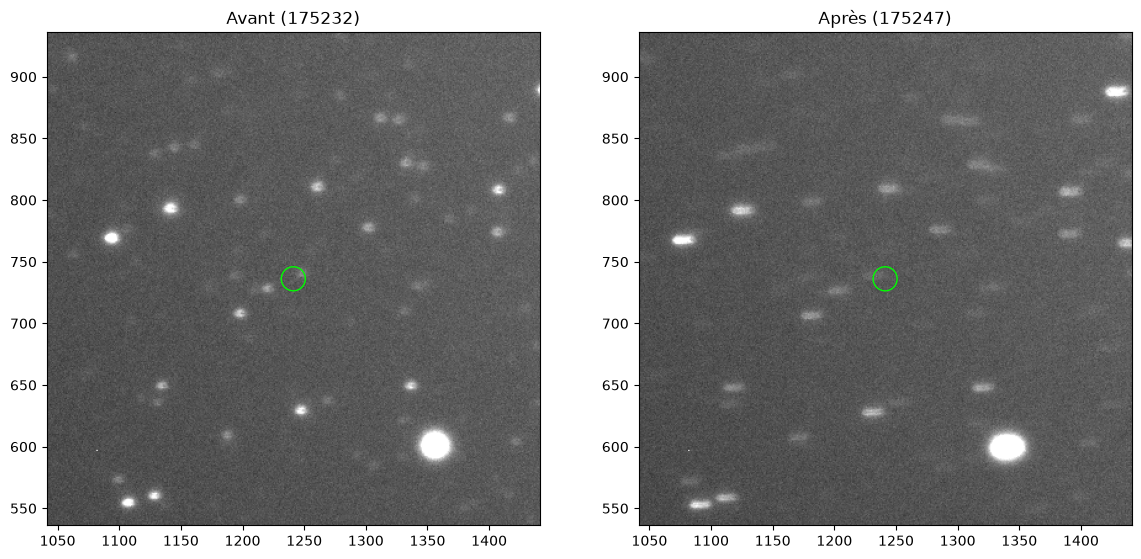

In [49]:
# On compare l'image juste avant le problème et l'image juste après

image_avant = fits.getdata("20261113T174736/20261113T175232.fits.fz", ext=1)
image_apres = fits.getdata("20261113T174736/20261113T175247.fits.fz", ext=1)

print("Médiane avant :", np.median(image_avant))
print("Médiane après :", np.median(image_apres))

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(image_avant, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
plt.scatter(x_vrai, y_vrai, s=300, edgecolor="lime", facecolor="none")
plt.xlim(x_vrai - 200, x_vrai + 200)
plt.ylim(y_vrai - 200, y_vrai + 200)
plt.title("Avant (175232)")

plt.subplot(1, 2, 2)
plt.imshow(image_apres, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
plt.scatter(x_vrai, y_vrai, s=300, edgecolor="lime", facecolor="none")
plt.xlim(x_vrai - 200, x_vrai + 200)
plt.ylim(y_vrai - 200, y_vrai + 200)
plt.title("Après (175247)")

plt.show()